# Experiment 8: Cross-Embodiment Transfer of a Manipulation Skill
**CSAI4014 AISR Laboratory** | Name: Suhani Baderia | SAP ID: 500119327 | Batch: 4

Everything here is simulated **in NumPy** (no PyBullet): four robot arms are modelled by their
Denavit–Hartenberg (DH) kinematics, a scripted expert performs a pick-and-place skill through each arm's own
inverse kinematics, and small neural-network policies are trained by behaviour cloning.

| Part | Question |
|---|---|
| 1 | What are the four embodiments and their workspaces? |
| 2 | Does replaying the KUKA's **joint** trajectory work on the other arms? |
| 3 | Does transferring the KUKA's **gripper (task-space)** path, tracked with each arm's own IK, work? |
| 4 | Learn a policy on the KUKA only, deploy it on all four arms (joint-space vs task-space actions). |
| 5 | Leave-one-embodiment-out: train on three arms, test on the unseen fourth. |

Simplifications (state these in the report): kinematics only (no dynamics, no contact forces), the grasp
succeeds when the gripper tip is within 1.5 cm of the cube centre, gripper orientation is not controlled,
and only gripper–table collision is checked.

Outputs: `results/*.csv`, `results/01_workspace.png … 05_multi_embodiment.png` (copied to `figs/`),
exercise outputs in `exercises/`.

In [1]:
import math
import os
import platform
import shutil
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

SEED = 9327                               # last 4 digits of SAP ID
N_DEMOS = 150                             # expert episodes per arm for training
N_TEST = 50                               # test tasks for every evaluation
for d in ("results", "figs", "exercises"):
    os.makedirs(d, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| Matplotlib:", matplotlib.__version__)
print("OS    :", platform.platform(), "| CPU:", platform.processor())

def save(fig, name):
    fig.savefig(os.path.join("results", name), bbox_inches="tight")
    shutil.copy(os.path.join("results", name), os.path.join("figs", name))

def save_table(rows, header, name):
    with open(os.path.join("results", name), "w", encoding="utf-8") as f:
        f.write(",".join(header) + "\n")
        for r in rows:
            f.write(",".join(str(x) for x in r) + "\n")
    w = [max(len(str(x)) for x in col) + 2 for col in zip(header, *rows)]
    print("".join(str(h).ljust(n) for h, n in zip(header, w)))
    for r in rows:
        print("".join(str(x).ljust(n) for x, n in zip(r, w)))

Python: 3.10.0 | NumPy: 1.26.4 | Matplotlib: 3.10.5
OS    : Windows-10-10.0.26300-SP0 | CPU: Intel64 Family 6 Model 170 Stepping 4, GenuineIntel


## Kinematic models
Forward kinematics chains one homogeneous transform per joint. Classic DH: $T_i = R_z(\theta_i)T_z(d_i)T_x(a_i)R_x(\alpha_i)$;
Craig (modified) DH, used for the Panda: $T_i = R_x(\alpha_{i-1})T_x(a_{i-1})R_z(\theta_i)T_z(d_i)$.
Position Jacobian column $i$: $J_i = z_i \times (p_{ee}-o_i)$. IK uses damped least squares
$\Delta q = J^T(JJ^T+\lambda^2 I)^{-1}\,e$ with $\lambda = 0.03$, clipped to the joint limits.
Every arm starts with its gripper at (0.40, 0, 0.35) m.

In [2]:
# ---------- Four embodiments, described by Denavit-Hartenberg parameters ----------
class Arm:
    """Serial arm from DH parameters. convention 'std' = classic DH, 'mod' = Craig (modified) DH."""

    def __init__(self, name, d, a, alpha, lo, hi, tool, convention="std", guess=None):
        self.name, self.conv = name, convention
        self.d, self.a, self.alpha = map(np.asarray, (d, a, alpha))
        self.lo, self.hi = np.asarray(lo, float), np.asarray(hi, float)
        self.tool, self.dof = tool, len(d)
        self.home = None
        self.guess = np.zeros(self.dof) if guess is None else np.asarray(guess, float)

    def fk_frames(self, q):
        """End-effector position plus the axis/origin of every joint (for the Jacobian)."""
        T = np.eye(4)
        axes, origins = [], []
        for i in range(self.dof):
            ca, sa = math.cos(self.alpha[i]), math.sin(self.alpha[i])
            ct, st = math.cos(q[i]), math.sin(q[i])
            if self.conv == "mod":       # Rx(alpha) Tx(a) then Rz(theta) Tz(d)
                T = T @ np.array([[1, 0, 0, self.a[i]], [0, ca, -sa, 0], [0, sa, ca, 0], [0, 0, 0, 1]])
                axes.append(T[:3, 2].copy()); origins.append(T[:3, 3].copy())
                T = T @ np.array([[ct, -st, 0, 0], [st, ct, 0, 0], [0, 0, 1, self.d[i]], [0, 0, 0, 1]])
            else:                        # Rz(theta) Tz(d) Tx(a) Rx(alpha)
                axes.append(T[:3, 2].copy()); origins.append(T[:3, 3].copy())
                T = T @ np.array([[ct, -st * ca, st * sa, self.a[i] * ct],
                                  [st, ct * ca, -ct * sa, self.a[i] * st],
                                  [0, sa, ca, self.d[i]], [0, 0, 0, 1]])
        ee = T[:3, 3] + self.tool * T[:3, 2]          # gripper tip, along the last z axis
        return ee, np.array(axes), np.array(origins)

    def fk(self, q):
        return self.fk_frames(q)[0]

    def jacobian(self, q):
        """3 x dof position Jacobian: column i = z_i x (p_ee - o_i) (all joints revolute)."""
        ee, z, o = self.fk_frames(q)
        return np.cross(z, ee - o).T, ee

    def ik_step(self, q, target, iters=3, lam=0.03):
        """Damped-least-squares IK: move q so that fk(q) approaches target; respects joint limits."""
        for _ in range(iters):
            J, ee = self.jacobian(q)
            e = target - ee
            if np.linalg.norm(e) < 1e-4:
                break
            dq = J.T @ np.linalg.solve(J @ J.T + lam ** 2 * np.eye(3), e)
            q = np.clip(q + np.clip(dq, -0.3, 0.3), self.lo, self.hi)
        return q


deg = np.radians
ARMS = [
    Arm("KUKA LBR iiwa 7", d=[0.34, 0, 0.40, 0, 0.40, 0, 0.126], a=[0] * 7,
        alpha=[-np.pi / 2, np.pi / 2, np.pi / 2, -np.pi / 2, -np.pi / 2, np.pi / 2, 0],
        lo=-deg([170, 120, 170, 120, 170, 120, 175]), hi=deg([170, 120, 170, 120, 170, 120, 175]), tool=0.10,
        guess=[0, 0.6, 0, -1.5, 0, 1.0, 0]),
    Arm("Franka Panda", d=[0.333, 0, 0.316, 0, 0.384, 0, 0], a=[0, 0, 0, 0.0825, -0.0825, 0, 0.088],
        alpha=[0, -np.pi / 2, np.pi / 2, np.pi / 2, -np.pi / 2, np.pi / 2, np.pi / 2],
        lo=[-2.8973, -1.7628, -2.8973, -3.0718, -2.8973, -0.0175, -2.8973],
        hi=[2.8973, 1.7628, 2.8973, -0.0698, 2.8973, 3.7525, 2.8973], tool=0.2104, convention="mod",
        guess=[0, 0.2, 0, -2.0, 0, 2.2, 0.785]),
    Arm("UR5", d=[0.089159, 0, 0, 0.10915, 0.09465, 0.0823], a=[0, -0.425, -0.39225, 0, 0, 0],
        alpha=[np.pi / 2, 0, 0, np.pi / 2, -np.pi / 2, 0],
        lo=[-2 * np.pi] * 6, hi=[2 * np.pi] * 6, tool=0.10, guess=[np.pi, -2.0, 1.6, -1.2, -1.57, 0]),
    Arm("Compact 5-DOF arm", d=[0.11, 0, 0, 0, 0.0], a=[0, 0.25, 0.25, 0, 0],
        alpha=[np.pi / 2, 0, 0, np.pi / 2, 0],
        lo=[-np.pi, 0.2, -2.6, -1.8, -2.8], hi=[np.pi, 2.9, 0.0, 1.8, 2.8], tool=0.16,
        guess=[0, 1.6, -1.5, -1.0, 0]),
]
HOME_POINT = np.array([0.40, 0.0, 0.35])          # every arm starts with its gripper here
for arm in ARMS:
    q = arm.guess.copy()
    for _ in range(100):
        q = arm.ik_step(q, HOME_POINT, iters=5)
    arm.home = q
    print(f"{arm.name:20s} dof {arm.dof}  home error {1000 * np.linalg.norm(arm.fk(q) - HOME_POINT):5.2f} mm")

KUKA LBR iiwa 7      dof 7  home error  0.02 mm
Franka Panda         dof 7  home error  0.00 mm
UR5                  dof 6  home error  0.01 mm
Compact 5-DOF arm    dof 5  home error  0.07 mm


## Task, expert and controllers
Pick a 5 cm cube from a random place on the table and put it on a random goal at least 15 cm away. The expert moves the gripper at most 2 cm per 0.05 s step toward a waypoint 10–12 cm above the target, descending once it is aligned.

In [3]:
# ---------- The manipulation skill: pick a 5 cm cube from the table and place it at a goal ----------
DT8 = 0.05                 # s per control step
MAX_STEP = 0.02            # m, largest gripper move per step
GRASP_TOL, PLACE_TOL = 0.015, 0.02     # m
MAX_STEPS = 160
CUBE_Z = 0.025             # cube centre height on the table (table top z = 0)


def sample_task(rng):
    """Cube and goal on the table in front of the robot, at least 15 cm apart."""
    while True:
        cube = np.array([rng.uniform(0.35, 0.65), rng.uniform(-0.30, 0.30), CUBE_Z])
        goal = np.array([rng.uniform(0.30, 0.65), rng.uniform(-0.35, 0.35), CUBE_Z])
        if np.linalg.norm(cube[:2] - goal[:2]) > 0.15:
            return cube, goal


def expert_target(ee, obj, goal, grasped):
    """Waypoint of the scripted expert: approach from above (10-12 cm) and descend when aligned."""
    tgt = goal if grasped else obj
    lift = 0.12 if grasped else 0.10
    hd = np.linalg.norm(tgt[:2] - ee[:2])
    return tgt + np.array([0, 0, lift * min(1.0, hd / 0.04)])


def clip_norm(v, m):
    n = np.linalg.norm(v)
    return v if n <= m else v * (m / n)


def expert_action(ee, obj, goal, grasped):
    return clip_norm(expert_target(ee, obj, goal, grasped) - ee, MAX_STEP)


def run_episode(arm, cube, goal, controller, max_steps=MAX_STEPS):
    """controller(arm, q, ee, obj, goal, grasped) -> new joint vector q.
    Returns dict(success, grasped, reason, path (T x 3), q (T x dof), final errors)."""
    q = arm.home.copy()
    ee = arm.fk(q)
    obj, grasped = cube.copy(), False
    path, qs = [ee], [q]
    reason = "timeout"
    for _ in range(max_steps):
        q = controller(arm, q, ee, obj, goal, grasped)
        ee = arm.fk(q)
        path.append(ee); qs.append(q)
        if ee[2] < -0.005:
            reason = "hit table"; break
        if not grasped and np.linalg.norm(ee - obj) < GRASP_TOL:
            grasped = True
        if grasped:
            obj = ee.copy()
            if np.linalg.norm(ee - goal) < PLACE_TOL:
                reason = "success"; break
    return {"success": reason == "success", "grasped": grasped, "reason": reason,
            "path": np.array(path), "q": np.array(qs),
            "grasp_err": np.min(np.linalg.norm(np.array(path) - cube, axis=1)),
            "place_err": np.linalg.norm(path[-1] - goal) if grasped else np.nan}


def expert_controller(arm, q, ee, obj, goal, grasped):
    return arm.ik_step(q, ee + expert_action(ee, obj, goal, grasped))


def replay_controller(q_traj):
    """Plays back a recorded joint trajectory step by step (extra joints dropped, limits enforced)."""
    it = iter(q_traj[1:])
    def ctrl(arm, q, ee, obj, goal, grasped):
        qk = next(it, q_traj[-1])
        out = q.copy()
        n = min(arm.dof, len(qk))
        out[:n] = qk[:n]
        return np.clip(out, arm.lo, arm.hi)
    return ctrl


def tracking_controller(ee_path):
    """Follows a recorded gripper path with the robot's own IK (task-space transfer)."""
    it = iter(ee_path[1:])
    def ctrl(arm, q, ee, obj, goal, grasped):
        return arm.ik_step(q, next(it, ee_path[-1]))
    return ctrl

## Behaviour-cloning policy (NumPy MLP, 2 × 128 tanh, Adam)
Two action spaces: **task space** (observation: cube and goal relative to the gripper; action: gripper displacement, executed by the robot's own IK) and **joint space** (observation: joint angles zero-padded to 7, cube, goal; action: joint increments).

In [4]:
# ---------- A small multilayer perceptron in NumPy (behaviour cloning) ----------
class MLP:
    def __init__(self, n_in, n_out, hidden=(128, 128), seed=0):
        rng = np.random.default_rng(seed)
        sizes = [n_in, *hidden, n_out]
        self.W = [rng.normal(0, np.sqrt(1 / a), (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros(b) for b in sizes[1:]]

    def forward(self, X):
        hs = [X]
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            X = X @ W + b
            if i < len(self.W) - 1:
                X = np.tanh(X)
            hs.append(X)
        return X, hs

    def fit(self, X, Y, mask=None, epochs=60, batch=256, lr=2e-3, seed=0):
        """Mean-squared error with optional per-output mask (for padded joint dimensions); Adam."""
        rng = np.random.default_rng(seed)
        self.mx, self.sx = X.mean(0), X.std(0) + 1e-6
        self.my, self.sy = Y.mean(0), Y.std(0) + 1e-6
        Xn, Yn = (X - self.mx) / self.sx, (Y - self.my) / self.sy
        M = np.ones_like(Yn) if mask is None else mask
        params = self.W + self.b
        m = [np.zeros_like(p) for p in params]
        v = [np.zeros_like(p) for p in params]
        t, losses = 0, []
        for ep in range(epochs):
            idx = rng.permutation(len(X))
            tot = 0.0
            for s in range(0, len(X), batch):
                bi = idx[s:s + batch]
                out, hs = self.forward(Xn[bi])
                err = (out - Yn[bi]) * M[bi]
                tot += (err ** 2).sum()
                g = 2 * err / len(bi)
                grads_W, grads_b = [], []
                for i in reversed(range(len(self.W))):
                    grads_W.insert(0, hs[i].T @ g)
                    grads_b.insert(0, g.sum(0))
                    if i > 0:
                        g = (g @ self.W[i].T) * (1 - hs[i] ** 2)
                t += 1
                for k, (p, gr) in enumerate(zip(params, grads_W + grads_b)):
                    m[k] = 0.9 * m[k] + 0.1 * gr
                    v[k] = 0.999 * v[k] + 0.001 * gr ** 2
                    p -= lr * (m[k] / (1 - 0.9 ** t)) / (np.sqrt(v[k] / (1 - 0.999 ** t)) + 1e-8)
            losses.append(tot / M.sum())
        return losses

    def __call__(self, x):
        out, _ = self.forward((np.atleast_2d(x) - self.mx) / self.sx)
        return (out * self.sy + self.my)[0]


# ----- observation / action encodings -----
QPAD = 7                                     # joint vectors are zero-padded to 7 entries


def obs_task(ee, obj, goal, grasped):
    """Task-space observation: where the cube and the goal are relative to the gripper."""
    return np.r_[obj - ee, goal - ee, float(grasped)]


def descriptor(arm):
    """Coarse embodiment descriptor given to the multi-robot joint-space policy."""
    return np.array([arm.dof / 7, ARM_REACH[arm.name]])


def obs_joint(arm, q, obj, goal, grasped, with_desc=False):
    qp = np.zeros(QPAD); qp[:arm.dof] = q
    o = np.r_[qp, obj, goal, float(grasped)]
    return np.r_[o, descriptor(arm)] if with_desc else o


def collect_demos(arm, n_episodes, rng):
    """Run the expert on one arm; keep successful episodes as (task obs, ee action, joint obs, dq)."""
    data = {"ot": [], "at": [], "oj": [], "oj_d": [], "aj": [], "mask": [], "ep": []}
    kept = 0
    for _ in range(n_episodes):
        cube, goal = sample_task(rng)
        rec = []
        def ctrl(arm_, q, ee, obj, goal_, grasped):
            a = expert_action(ee, obj, goal_, grasped)
            qn = arm_.ik_step(q, ee + a)
            rec.append((q, ee, obj.copy(), grasped, a, qn - q))
            return qn
        if run_episode(arm, cube, goal, ctrl)["success"]:
            for q, ee, obj, grasped, a, dq in rec:
                data["ot"].append(obs_task(ee, obj, goal, grasped)); data["at"].append(a)
                data["oj"].append(obs_joint(arm, q, obj, goal, grasped))
                data["oj_d"].append(obs_joint(arm, q, obj, goal, grasped, True))
                dqp = np.zeros(QPAD); dqp[:arm.dof] = dq
                mk = np.zeros(QPAD); mk[:arm.dof] = 1
                data["aj"].append(dqp); data["mask"].append(mk); data["ep"].append(kept)
            kept += 1
    return {k: np.array(v) for k, v in data.items()}, kept


def merge(datasets):
    return {k: np.concatenate([d[k] for d in datasets]) for k in datasets[0]}


def task_policy_controller(policy):
    def ctrl(arm, q, ee, obj, goal, grasped):
        a = clip_norm(policy(obs_task(ee, obj, goal, grasped)), MAX_STEP)
        return arm.ik_step(q, ee + a)
    return ctrl


def joint_policy_controller(policy, with_desc=False):
    def ctrl(arm, q, ee, obj, goal, grasped):
        dq = policy(obs_joint(arm, q, obj, goal, grasped, with_desc))[:arm.dof]
        return np.clip(q + np.clip(dq, -0.3, 0.3), arm.lo, arm.hi)
    return ctrl


def evaluate(arm, controller, tasks):
    res = [run_episode(arm, c, g, controller) for c, g in tasks]
    return 100 * np.mean([r["success"] for r in res]), res

## Part 1 – The four embodiments (Table 8.1, Figure 8.1)

Robot              DOF  Kinematics  Shoulder height (m)  Max reach from shoulder (m)  Task region reachable (%)  Home joint angles (rad)                    
KUKA LBR iiwa 7    7    classic DH  0.340                1.026                        100                        +0.00 +0.19 +0.00 -1.79 +0.00 +1.35 +0.00  
Franka Panda       7    Craig DH    0.333                0.947                        100                        +0.00 -0.32 +0.00 -2.32 +0.00 +1.77 +0.79  
UR5                6    classic DH  0.089                1.029                        100                        +2.92 -1.72 +1.63 -1.31 -1.68 -0.00        
Compact 5-DOF arm  5    classic DH  0.110                0.660                        78                         -0.00 +1.11 -0.46 -0.06 -0.00              


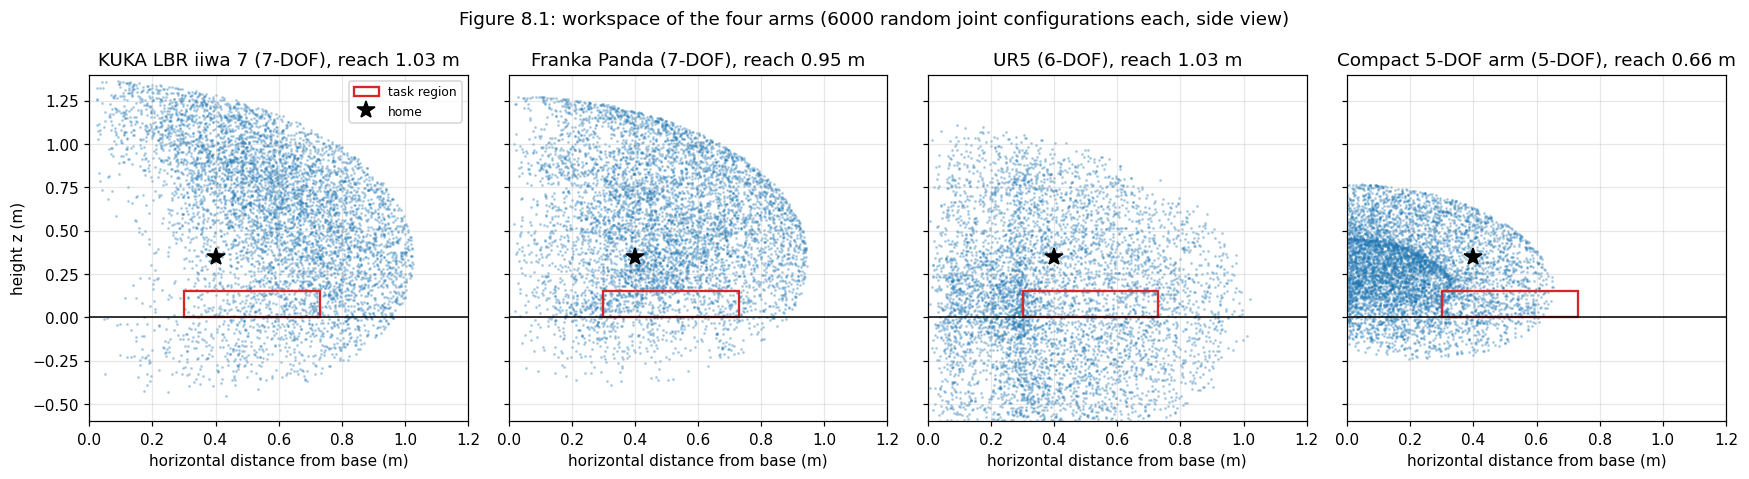

In [5]:
rng = np.random.default_rng(SEED)
ARM_REACH, ws = {}, {}
grid = [np.array([x, y, CUBE_Z]) for x in np.linspace(0.30, 0.65, 8) for y in np.linspace(-0.35, 0.35, 8)]
rows = []
for arm in ARMS:
    Q = rng.uniform(arm.lo, arm.hi, (6000, arm.dof))
    P = np.array([arm.fk(q) for q in Q])
    shoulder = arm.fk_frames(arm.home)[2][1]
    ARM_REACH[arm.name] = float(np.max(np.linalg.norm(P - shoulder, axis=1)))
    ws[arm.name] = P
    ok = 0
    for p in grid:                                  # can its IK reach each table point of the task region?
        q = arm.home.copy()
        for _ in range(60):
            q = arm.ik_step(q, p, iters=3)
        ok += np.linalg.norm(arm.fk(q) - p) < 0.005
    rows.append([arm.name, arm.dof, "Craig DH" if arm.conv == "mod" else "classic DH", f"{shoulder[2]:.3f}",
                 f"{ARM_REACH[arm.name]:.3f}", f"{100 * ok / len(grid):.0f}",
                 " ".join(f"{v:+.2f}" for v in arm.home)])
save_table(rows, ["Robot", "DOF", "Kinematics", "Shoulder height (m)", "Max reach from shoulder (m)",
                  "Task region reachable (%)", "Home joint angles (rad)"], "T8_1_embodiments.csv")

fig, axs = plt.subplots(1, 4, figsize=(16, 4.4), sharey=True)
for ax, arm in zip(axs, ARMS):
    P = ws[arm.name]
    r = np.hypot(P[:, 0], P[:, 1])
    ax.scatter(r, P[:, 2], s=1, alpha=0.25, color="tab:blue")
    ax.axhline(0, color="k", lw=1)
    ax.add_patch(plt.Rectangle((0.30, 0.0), 0.43, 0.15, fill=False, ec="tab:red", lw=1.5, label="task region"))
    h = arm.fk(arm.home)
    ax.plot(np.hypot(h[0], h[1]), h[2], "k*", ms=12, label="home")
    ax.set(title=f"{arm.name} ({arm.dof}-DOF), reach {ARM_REACH[arm.name]:.2f} m",
           xlabel="horizontal distance from base (m)", xlim=(0, 1.2), ylim=(-0.6, 1.4))
    ax.grid(alpha=0.3)
axs[0].set_ylabel("height z (m)")
axs[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Figure 8.1: workspace of the four arms (6000 random joint configurations each, side view)")
fig.tight_layout()
save(fig, "01_workspace.png")
plt.show()

## Part 2 – Joint-space replay of KUKA trajectories (Table 8.2, Figure 8.2)
The KUKA expert solves each test task; its joint trajectory is then played back on every arm (first *n* joints used, limits enforced).

KUKA expert success on the 50 test tasks: 100%


Robot              Success (%)  Cube grasped (%)  Closest approach to cube (cm)  Mean deviation from KUKA path (cm)  Episode outcomes (of 50)  
KUKA LBR iiwa 7    100          100               0.6                            0.0                                 success 50                
Franka Panda       0            0                 17.6                           9.7                                 timeout 50                
UR5                0            0                 39.6                           69.9                                hit table 50              
Compact 5-DOF arm  0            0                 32.8                           32.9                                timeout 50                


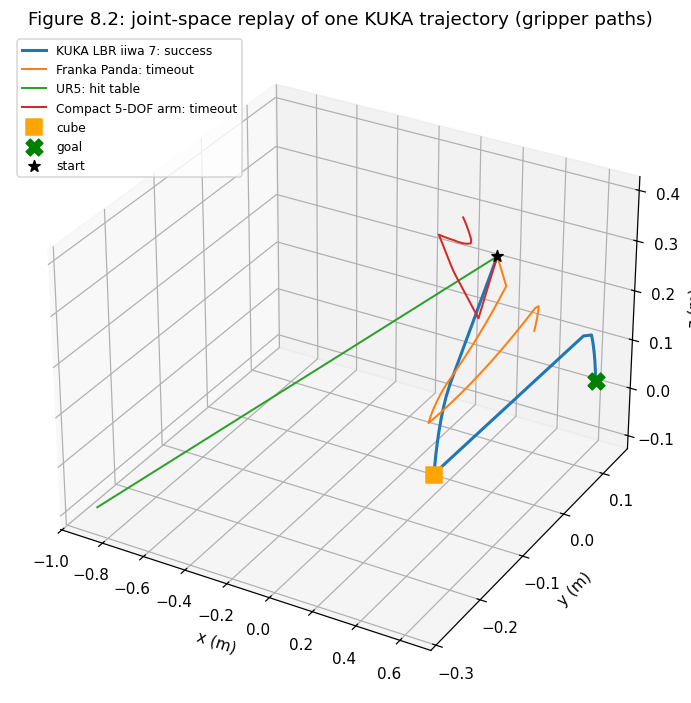

In [6]:
rng_test = np.random.default_rng(SEED + 1)
TEST = [sample_task(rng_test) for _ in range(N_TEST)]
KUKA = ARMS[0]
kuka_runs = [run_episode(KUKA, c, g, expert_controller) for c, g in TEST]
print(f"KUKA expert success on the {N_TEST} test tasks: {100 * np.mean([r['success'] for r in kuka_runs]):.0f}%")

def transfer_table(make_ctrl, fname, title):
    rows, example = [], {}
    for arm in ARMS:
        res = [run_episode(arm, c, g, make_ctrl(k)) for k, (c, g) in enumerate(TEST)]
        dev = [np.mean(np.linalg.norm(r["path"][:len(kr["path"])] - kr["path"][:len(r["path"])], axis=1))
               for r, kr in zip(res, kuka_runs)]
        rows.append([arm.name, f"{100 * np.mean([r['success'] for r in res]):.0f}",
                     f"{100 * np.mean([r['grasped'] for r in res]):.0f}",
                     f"{100 * np.mean([r['grasp_err'] for r in res]):.1f}",
                     f"{100 * np.mean(dev):.1f}",
                     "; ".join(f"{k} {v}" for k, v in sorted(Counter(r['reason'] for r in res).items()))])
        example[arm.name] = res[0]
    save_table(rows, ["Robot", "Success (%)", "Cube grasped (%)", "Closest approach to cube (cm)",
                      "Mean deviation from KUKA path (cm)", "Episode outcomes (of 50)"], fname)
    return example

def plot_paths(example, title, name):
    fig = plt.figure(figsize=(8, 6.5))
    ax = fig.add_subplot(projection="3d")
    c, g = TEST[0]
    for i, arm in enumerate(ARMS):
        p = example[arm.name]["path"]
        ax.plot(p[:, 0], p[:, 1], p[:, 2], color=f"C{i}", lw=2 if i == 0 else 1.3,
                label=f"{arm.name}: {example[arm.name]['reason']}")
    ax.scatter(*c, s=120, marker="s", color="orange", label="cube")
    ax.scatter(*g, s=120, marker="X", color="green", label="goal")
    ax.scatter(*HOME_POINT, s=60, marker="*", color="k", label="start")
    ax.set(xlabel="x (m)", ylabel="y (m)", zlabel="z (m)", title=title)
    ax.legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    save(fig, name)
    plt.show()

from collections import Counter
ex2 = transfer_table(lambda k: replay_controller(kuka_runs[k]["q"]), "T8_2_joint_space_replay.csv", "")
plot_paths(ex2, "Figure 8.2: joint-space replay of one KUKA trajectory (gripper paths)", "02_joint_space_paths.png")

## Part 3 – Task-space transfer of the expert (Table 8.3, Figure 8.3)
Same tasks, but each arm follows the KUKA's **gripper path** with its own IK.

Robot              Success (%)  Cube grasped (%)  Closest approach to cube (cm)  Mean deviation from KUKA path (cm)  Episode outcomes (of 50)  
KUKA LBR iiwa 7    100          100               0.6                            0.0                                 success 50                
Franka Panda       100          100               0.6                            0.0                                 success 50                
UR5                100          100               0.6                            0.0                                 success 50                
Compact 5-DOF arm  66           72                1.5                            0.3                                 success 33; timeout 17    


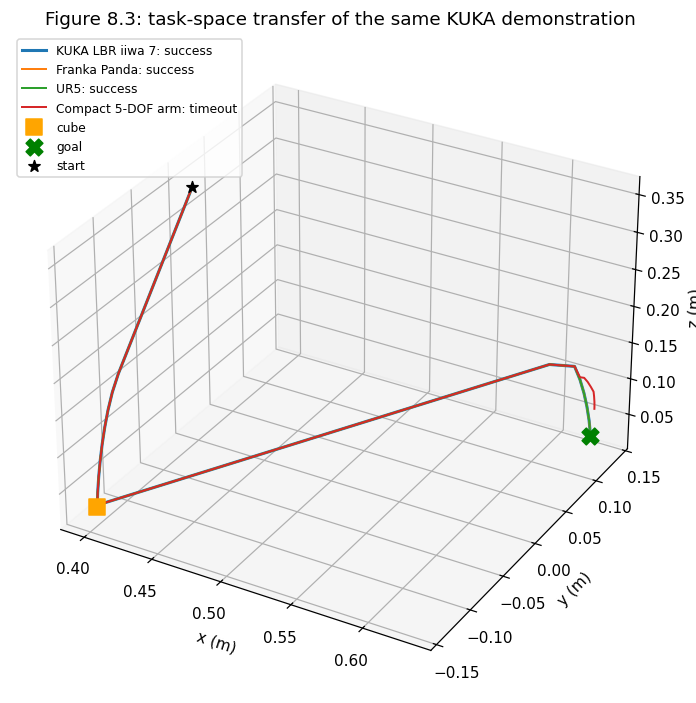

In [7]:
ex3 = transfer_table(lambda k: tracking_controller(kuka_runs[k]["path"]), "T8_3_task_space_transfer.csv", "")
plot_paths(ex3, "Figure 8.3: task-space transfer of the same KUKA demonstration", "03_task_space_paths.png")

## Part 4 – Learn on KUKA, deploy everywhere (Table 8.4, Figure 8.4)
Expert demonstrations are collected on the KUKA only; both policies are trained on them and deployed on all four arms.

KUKA LBR iiwa 7      demos kept 150/150  samples 6032


Franka Panda         demos kept 150/150  samples 6172


UR5                  demos kept 150/150  samples 6152


Compact 5-DOF arm    demos kept 111/150  samples 4727


trained in 20 s; final normalised loss: task 0.0051, joint 0.0099


Robot              Expert on this robot (%)  Joint-space policy, trained on KUKA (%)  Task-space policy, trained on KUKA (%)  
KUKA LBR iiwa 7    100                       46                                       100                                     
Franka Panda       100                       0                                        100                                     
UR5                100                       0                                        100                                     
Compact 5-DOF arm  76                        0                                        64                                      


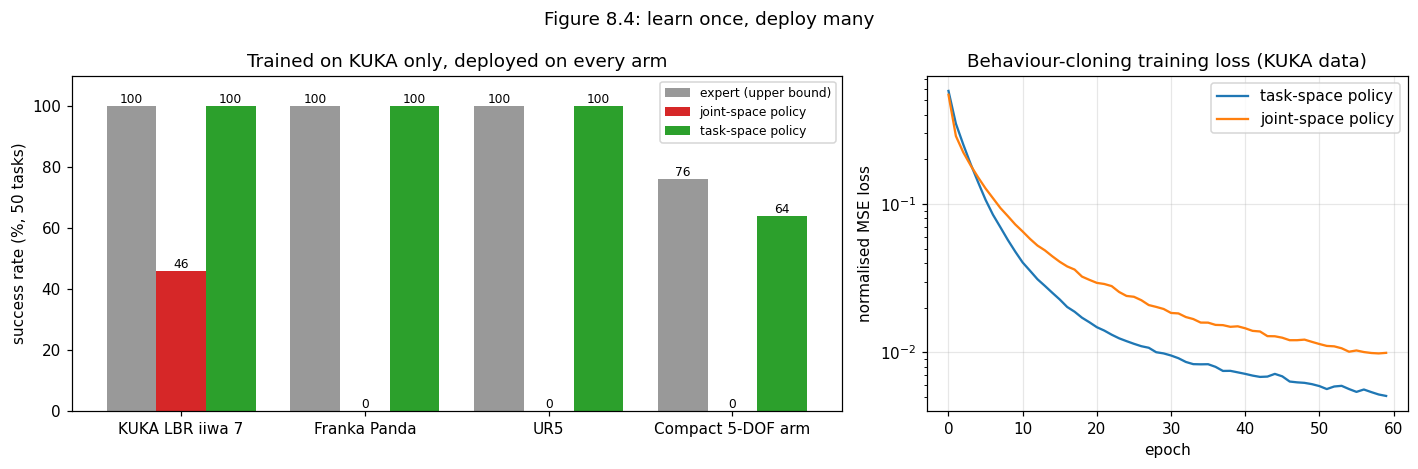

In [8]:
t0 = time.time()
DEMOS = {}
for i, arm in enumerate(ARMS):
    DEMOS[arm.name], kept = collect_demos(arm, N_DEMOS, np.random.default_rng(SEED + 10 + i))
    print(f"{arm.name:20s} demos kept {kept}/{N_DEMOS}  samples {len(DEMOS[arm.name]['ot'])}")
D = DEMOS[KUKA.name]
pol_task = MLP(7, 3, seed=SEED)
loss_task = pol_task.fit(D["ot"], D["at"], seed=SEED)
pol_joint = MLP(14, QPAD, seed=SEED)
loss_joint = pol_joint.fit(D["oj"], D["aj"], mask=D["mask"], seed=SEED)
print(f"trained in {time.time() - t0:.0f} s; final normalised loss: task {loss_task[-1]:.4f}, joint {loss_joint[-1]:.4f}")

rows4, succ4 = [], {}
for arm in ARMS:
    e, _ = evaluate(arm, expert_controller, TEST)
    j, _ = evaluate(arm, joint_policy_controller(pol_joint), TEST)
    t, _ = evaluate(arm, task_policy_controller(pol_task), TEST)
    succ4[arm.name] = (e, j, t)
    rows4.append([arm.name, f"{e:.0f}", f"{j:.0f}", f"{t:.0f}"])
save_table(rows4, ["Robot", "Expert on this robot (%)", "Joint-space policy, trained on KUKA (%)",
                   "Task-space policy, trained on KUKA (%)"], "T8_4_learn_on_kuka.csv")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})
x = np.arange(len(ARMS))
for k, (lab, col) in enumerate([("expert (upper bound)", "0.6"), ("joint-space policy", "tab:red"),
                                ("task-space policy", "tab:green")]):
    v = [succ4[a.name][k] for a in ARMS]
    b = a1.bar(x + (k - 1) * 0.27, v, 0.27, label=lab, color=col)
    a1.bar_label(b, fmt="%.0f", fontsize=8)
a1.set(xticks=x, xticklabels=[a.name for a in ARMS], ylabel=f"success rate (%, {N_TEST} tasks)", ylim=(0, 110),
       title="Trained on KUKA only, deployed on every arm")
a1.legend(fontsize=8)
a2.semilogy(loss_task, label="task-space policy")
a2.semilogy(loss_joint, label="joint-space policy")
a2.set(xlabel="epoch", ylabel="normalised MSE loss", title="Behaviour-cloning training loss (KUKA data)")
a2.legend(); a2.grid(alpha=0.3)
fig.suptitle("Figure 8.4: learn once, deploy many")
fig.tight_layout()
save(fig, "04_learn_once_deploy_many.png")
plt.show()

## Part 5 – Leave-one-embodiment-out (Table 8.5, Figure 8.5)
For each arm: train on the other three (joint-space policy gets a coarse descriptor = [DOF/7, reach]), test on the unseen arm.

held out KUKA LBR iiwa 7 done


held out Franka Panda done


held out UR5 done


held out Compact 5-DOF arm done
Unseen robot       Trained on               Joint-space multi policy on a seen robot (%)  Joint-space multi policy on unseen (%)  Task-space multi policy on unseen (%)  Task-space KUKA-only policy (%)  Expert (%)  
KUKA LBR iiwa 7    Franka + UR5 + Compact   42                                            0                                       100                                    100                              100         
Franka Panda       KUKA + UR5 + Compact     16                                            0                                       100                                    100                              100         
UR5                KUKA + Franka + Compact  40                                            0                                       100                                    100                              100         
Compact 5-DOF arm  KUKA + Franka + UR5      52                                            0                 

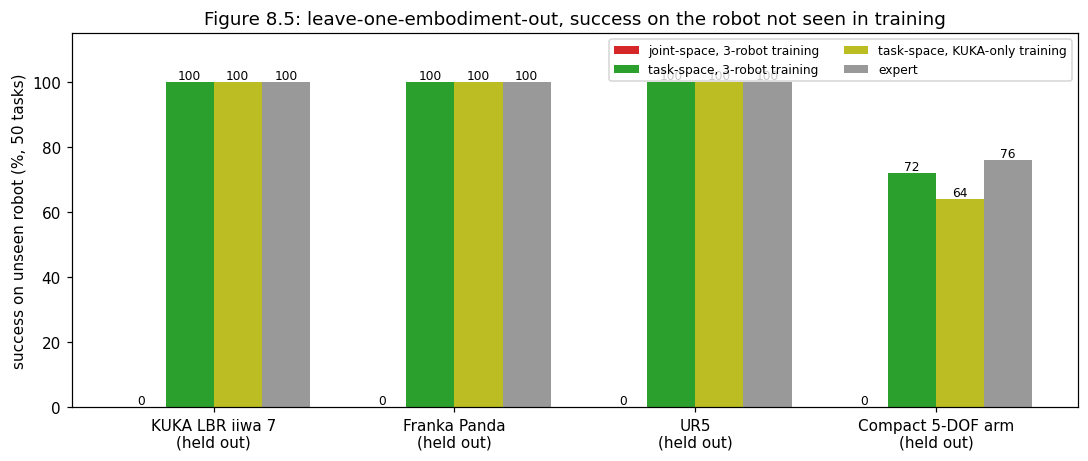

In [9]:
rows5, succ5 = [], {}
for k, held in enumerate(ARMS):
    train_arms = [a for a in ARMS if a is not held]
    Dm = merge([DEMOS[a.name] for a in train_arms])
    pj = MLP(16, QPAD, seed=SEED + k); pj.fit(Dm["oj_d"], Dm["aj"], mask=Dm["mask"], seed=SEED)
    pt = MLP(7, 3, seed=SEED + k); pt.fit(Dm["ot"], Dm["at"], seed=SEED)
    j, _ = evaluate(held, joint_policy_controller(pj, with_desc=True), TEST)
    t, _ = evaluate(held, task_policy_controller(pt), TEST)
    j_seen, _ = evaluate(train_arms[0], joint_policy_controller(pj, with_desc=True), TEST)
    succ5[held.name] = (j, t, succ4[held.name][2], succ4[held.name][0])
    rows5.append([held.name, " + ".join(a.name.split()[0] for a in train_arms), f"{j_seen:.0f}", f"{j:.0f}",
                  f"{t:.0f}", f"{succ4[held.name][2]:.0f}", f"{succ4[held.name][0]:.0f}"])
    print(f"held out {held.name} done")
save_table(rows5, ["Unseen robot", "Trained on", f"Joint-space multi policy on a seen robot (%)",
                   "Joint-space multi policy on unseen (%)", "Task-space multi policy on unseen (%)",
                   "Task-space KUKA-only policy (%)", "Expert (%)"], "T8_5_leave_one_out.csv")

fig, ax = plt.subplots(figsize=(10, 4.3))
for k, (lab, col) in enumerate([("joint-space, 3-robot training", "tab:red"),
                                ("task-space, 3-robot training", "tab:green"),
                                ("task-space, KUKA-only training", "tab:olive"), ("expert", "0.6")]):
    v = [succ5[a.name][k] for a in ARMS]
    b = ax.bar(x + (k - 1.5) * 0.2, v, 0.2, label=lab, color=col)
    ax.bar_label(b, fmt="%.0f", fontsize=8)
ax.set(xticks=x, xticklabels=[f"{a.name}\n(held out)" for a in ARMS], ylabel=f"success on unseen robot (%, {N_TEST} tasks)",
       ylim=(0, 115), title="Figure 8.5: leave-one-embodiment-out, success on the robot not seen in training")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, "05_multi_embodiment.png")
plt.show()

## Exercise A – robustness: noise on the cube/goal position estimate
Gaussian noise (σ) is added to the cube and goal positions the task-space policy observes (a stand-in for an imperfect camera). Policy trained on KUKA only.

sigma(cm) KUKA LBR iiw  Franka Panda           UR5  Compact 5-DO
    0.00           100           100           100            64
    0.25           100           100           100            68
    0.50           100           100           100            72
    1.00           100           100           100            74
    2.00            74            74            74            56


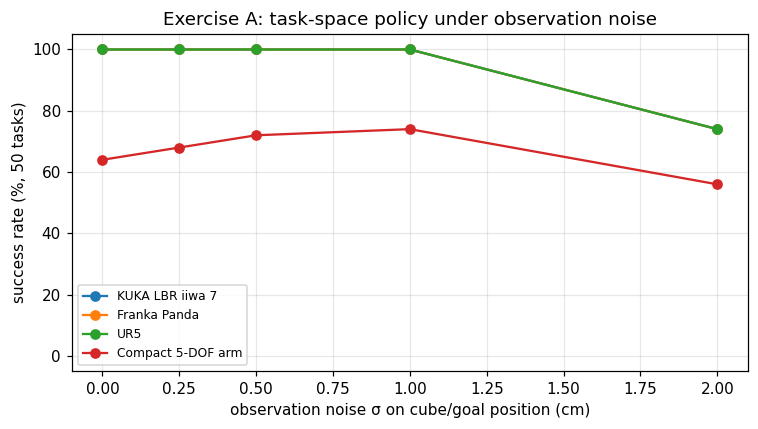

In [10]:
def noisy_task_controller(policy, sigma, rng):
    def ctrl(arm, q, ee, obj, goal, grasped):
        o, gl = obj + rng.normal(0, sigma, 3), goal + rng.normal(0, sigma, 3)
        return arm.ik_step(q, ee + clip_norm(policy(obs_task(ee, o, gl, grasped)), MAX_STEP))
    return ctrl

SIGMAS = [0.0, 0.0025, 0.005, 0.01, 0.02]
exA = []
for s in SIGMAS:
    row = [s * 100]
    for arm in ARMS:
        v, _ = evaluate(arm, noisy_task_controller(pol_task, s, np.random.default_rng(SEED)), TEST)
        row.append(v)
    exA.append(row)
exA = np.array(exA)
np.savetxt("exercises/EA_noise_robustness.csv", exA, fmt="%.1f", delimiter=",",
           header="noise sigma (cm)," + ",".join(a.name + " success %" for a in ARMS), comments="")
print("sigma(cm) " + "  ".join(f"{a.name[:12]:>12}" for a in ARMS))
for r in exA:
    print(f"{r[0]:8.2f}  " + "  ".join(f"{v:12.0f}" for v in r[1:]))
fig, ax = plt.subplots(figsize=(7, 4))
for i, arm in enumerate(ARMS):
    ax.plot(exA[:, 0], exA[:, i + 1], "o-", label=arm.name)
ax.set(xlabel="observation noise σ on cube/goal position (cm)", ylabel=f"success rate (%, {N_TEST} tasks)",
       title="Exercise A: task-space policy under observation noise", ylim=(-5, 105))
ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("exercises/EA_noise_robustness.png"); plt.show()

## Exercise B – data efficiency: how many KUKA demonstrations are needed?

demos  samples KUKA LBR iiw  Franka Panda           UR5  Compact 5-DO
    5      202            0             0             0             0
   10      420           10            10             8             8
   25      995           78            78            78            50
   50     2039           94            94            94            60
  100     4084          100           100           100            66
  150     6032          100           100           100            64


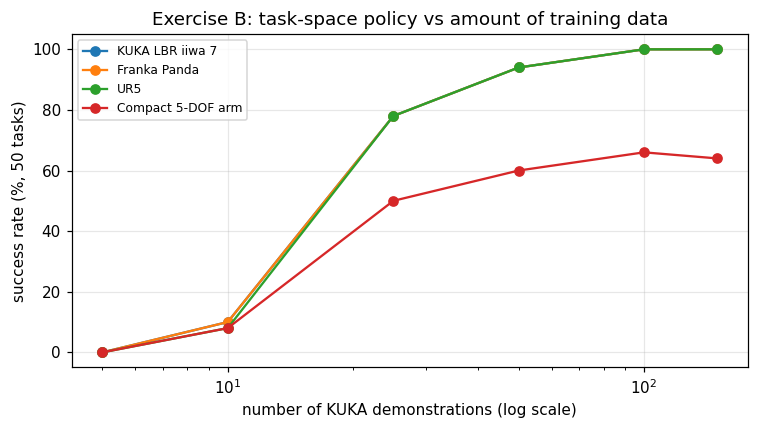

In [11]:
N_LIST = [5, 10, 25, 50, 100, N_DEMOS]
Dk, exB = DEMOS[KUKA.name], []
for n in N_LIST:
    sel = Dk["ep"] < n                                # first n successful demonstrations
    m = int(sel.sum())
    p = MLP(7, 3, seed=SEED); p.fit(Dk["ot"][sel], Dk["at"][sel], seed=SEED, epochs=60)
    exB.append([n, m] + [evaluate(a, task_policy_controller(p), TEST)[0] for a in ARMS])
exB = np.array(exB, float)
np.savetxt("exercises/EB_data_efficiency.csv", exB, fmt="%.0f", delimiter=",",
           header="KUKA demos,training samples," + ",".join(a.name + " success %" for a in ARMS), comments="")
print("demos  samples " + "  ".join(f"{a.name[:12]:>12}" for a in ARMS))
for r in exB:
    print(f"{r[0]:5.0f}  {r[1]:7.0f} " + "  ".join(f"{v:12.0f}" for v in r[2:]))
fig, ax = plt.subplots(figsize=(7, 4))
for i, arm in enumerate(ARMS):
    ax.plot(exB[:, 0], exB[:, i + 2], "o-", label=arm.name)
ax.set_xscale("log")
ax.set(xlabel="number of KUKA demonstrations (log scale)", ylabel=f"success rate (%, {N_TEST} tasks)",
       title="Exercise B: task-space policy vs amount of training data", ylim=(-5, 105))
ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("exercises/EB_data_efficiency.png"); plt.show()

## Result (Section 10), generated from this run

In [12]:
names = [a.name for a in ARMS]
t2 = {r[0]: r[1] for r in np.genfromtxt("results/T8_2_joint_space_replay.csv", delimiter=",", dtype=str, skip_header=1)}
t3 = {r[0]: r[1] for r in np.genfromtxt("results/T8_3_task_space_transfer.csv", delimiter=",", dtype=str, skip_header=1)}
print(f"1. Replaying the KUKA joint trajectory succeeded on " + ", ".join(f"{n} {t2[n]}%" for n in names) +
      " - joint angles mean different things on different kinematic chains.")
print(f"2. Transferring the gripper path instead and tracking it with each arm's own IK gave " +
      ", ".join(f"{n} {t3[n]}%" for n in names) + "; failures are targets outside the arm's reach.")
print(f"3. A policy trained only on KUKA data transfers when it acts in task space (" +
      ", ".join(f"{n} {succ4[n][2]:.0f}%" for n in names) + ") but not in joint space (" +
      ", ".join(f"{n} {succ4[n][1]:.0f}%" for n in names) + ").")
print(f"4. Leave-one-out: the joint-space policy trained on three arms reached " +
      ", ".join(f"{n} {succ5[n][0]:.0f}%" for n in names) + " on the unseen arm; the task-space one " +
      ", ".join(f"{n} {succ5[n][1]:.0f}%" for n in names) + ".")
print("5. The interface (task-space action + robot-specific IK) carries the skill across bodies; reach and "
      "joint limits of the target robot set the ceiling, which matches the expert's own success on that robot.")

1. Replaying the KUKA joint trajectory succeeded on KUKA LBR iiwa 7 100%, Franka Panda 0%, UR5 0%, Compact 5-DOF arm 0% - joint angles mean different things on different kinematic chains.
2. Transferring the gripper path instead and tracking it with each arm's own IK gave KUKA LBR iiwa 7 100%, Franka Panda 100%, UR5 100%, Compact 5-DOF arm 66%; failures are targets outside the arm's reach.
3. A policy trained only on KUKA data transfers when it acts in task space (KUKA LBR iiwa 7 100%, Franka Panda 100%, UR5 100%, Compact 5-DOF arm 64%) but not in joint space (KUKA LBR iiwa 7 46%, Franka Panda 0%, UR5 0%, Compact 5-DOF arm 0%).
4. Leave-one-out: the joint-space policy trained on three arms reached KUKA LBR iiwa 7 0%, Franka Panda 0%, UR5 0%, Compact 5-DOF arm 0% on the unseen arm; the task-space one KUKA LBR iiwa 7 100%, Franka Panda 100%, UR5 100%, Compact 5-DOF arm 72%.
5. The interface (task-space action + robot-specific IK) carries the skill across bodies; reach and joint limits of